In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter

import tensorflow as tf

#for your homework
np.random.seed(10327798)
tf.random.set_seed(10327798)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


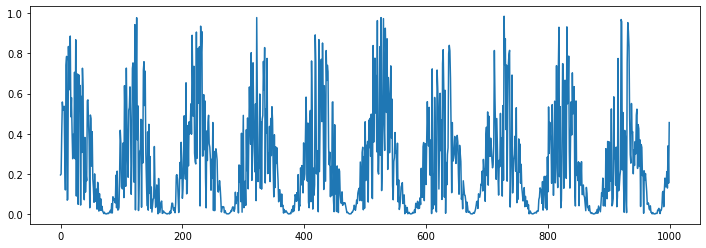

In [ ]:
#generate an artificial dataset that is amplitude-modulated white noise
from numpy.random import default_rng
rng = default_rng()
time_points = 10000
wave_signal = 0.5 * (1.0+np.sin(np.linspace(0,2*np.pi*100, time_points)))
random_signal = rng.random(time_points)  #values in 0...1
modulated_signal = np.multiply(wave_signal,random_signal)
plt.figure(figsize=(12,4), linewidth = 1)
plt.plot(modulated_signal[0:1000]);

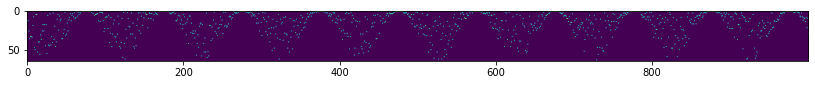

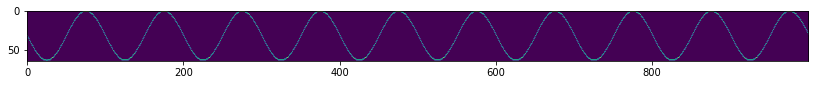

In [ ]:
#encode the state in a state vector representing the probabilities.  These are the actual measured states, so prob=1 for the correct state
#however, the states here are not integers, so we need to interpolate
def to_distributed(data, nstates=128, timepoints=1000):
  d = data - min(data)
  dscale = ((nstates-1)*d/np.max(d))
  vec = np.zeros((timepoints, nstates), dtype = int)
  vec[np.arange(timepoints),dscale.astype(int)] = 1
  return vec

n_states = 64   #this is arbitrary. sets the precision
vModulated = to_distributed(modulated_signal, n_states, time_points)
dfModulated = pd.DataFrame(data=vModulated, index=np.arange(time_points))
plt.figure(figsize=(14,1))
plt.imshow(vModulated[0:1000,:].transpose())
vWave = to_distributed(wave_signal, n_states, time_points)
dfWave = pd.DataFrame(data=vWave, index=np.arange(time_points))
plt.figure(figsize=(14,1))
plt.imshow(vWave[0:1000,:].transpose());

In [ ]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
n_features = n_states
n_hidden = n_states
predict_length = 1
model = Sequential()
model.add(Flatten(input_shape = (1,n_features)))
model.add(Dense(n_features, activation='softmax'))
model.compile(optimizer='adam', loss='categorical_crossentropy')
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 64)                4160      
                                                                 
Total params: 4,160
Trainable params: 4,160
Non-trainable params: 0
_________________________________________________________________


Epoch 1/10
563/563 [==============================] - 2s 3ms/step - loss: 3.9839 - val_loss: 3.8112
Epoch 2/10
563/563 [==============================] - 1s 3ms/step - loss: 3.6525 - val_loss: 3.5542
Epoch 3/10
563/563 [==============================] - 1s 2ms/step - loss: 3.4279 - val_loss: 3.3910
Epoch 4/10
563/563 [==============================] - 1s 2ms/step - loss: 3.2870 - val_loss: 3.2970
Epoch 5/10
563/563 [==============================] - 1s 2ms/step - loss: 3.1987 - val_loss: 3.2403
Epoch 6/10
563/563 [==============================] - 1s 2ms/step - loss: 3.1376 - val_loss: 3.2013
Epoch 7/10
563/563 [==============================] - 1s 2ms/step - loss: 3.0905 - val_loss: 3.1732
Epoch 8/10
563/563 [==============================] - 1s 2ms/step - loss: 3.0523 - val_loss: 3.1519
Epoch 9/10
563/563 [==============================] - 1s 2ms/step - loss: 3.0206 - val_loss: 3.1358
Epoch 10/10
563/563 [==============================] - 1s 2ms/step - loss: 2.9939 - val_loss: 3.1238

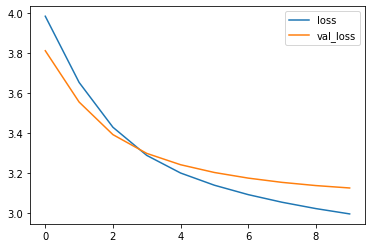

In [ ]:
#need to reshape the input data because numpy expects a 1xn_states array, rather than a vector of n_states.  this is why I use matlab.
model.fit(vWave.reshape(time_points,1,n_states),vModulated, validation_split=0.1, batch_size=16, epochs=10, verbose=1)
#model.fit(generator, epochs=5)  #if you want to do these in time sequence, which does not matter here
losses = pd.DataFrame(model.history.history)
losses.plot()

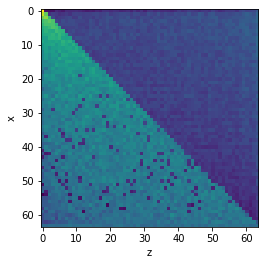

In [ ]:

#pzx = np.maximum(model.weights[0], np.zeros(model.weights[0].shape))
pzx = np.exp(model.weights[0])
row_sums = pzx.sum(axis=1)
pzx = pzx / row_sums.reshape(n_states,1);
plt.imshow(np.log(pzx))
plt.xlabel('z')
plt.ylabel('x');



In [ ]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = 1
generator = TimeseriesGenerator(dfWave.values, dfWave.values, length =predict_length , batch_size=16)
#NOTE1:  you have to use df.values or you get weird indexing errors


In [ ]:
#same model, but we have to recreate it otherwise will start with the weights from the last one
n_features = n_states
n_hidden = n_states
predict_length = 1
model = Sequential()
model.add(Flatten(input_shape = (1,n_features)))
model.add(Dense(n_features, activation='softmax'))
model.compile(optimizer='adam', loss='categorical_crossentropy')
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 64)                0         
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
Total params: 4,160
Trainable params: 4,160
Non-trainable params: 0
_________________________________________________________________


In [ ]:
#we can use the same model here
model.fit(generator, epochs=5)

Epoch 1/5
625/625 [==============================] - 2s 3ms/step - loss: 3.9387
Epoch 2/5
625/625 [==============================] - 2s 3ms/step - loss: 3.4592
Epoch 3/5
625/625 [==============================] - 2s 3ms/step - loss: 3.0272
Epoch 4/5
625/625 [==============================] - 2s 3ms/step - loss: 2.6482
Epoch 5/5
625/625 [==============================] - 2s 3ms/step - loss: 2.3255


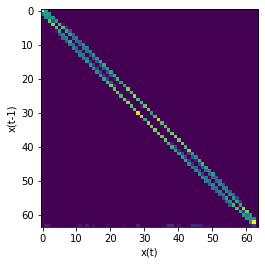

In [ ]:
use_exponential = 0
if use_exponential:
  pxx = np.exp(model.weights[0])
else:
  pxx = np.maximum(model.weights[0], np.zeros(model.weights[0].shape))  #values need to be positive
row_sums = pxx.sum(axis=1)
row_sums[row_sums==0]=1   #just in case there was no data
pxx = pxx / row_sums.reshape(n_states,1);
if use_exponential:
  plt.imshow(np.log(pxx))
else:
  plt.imshow(pxx)
plt.xlabel('x(t)')
plt.ylabel('x(t-1)');

In [ ]:
#if the values are zero, the system can fail when it predicts zero probability of an observation p(z|x).
#Always needs to be some possibility of an observation, no matter how unlikely.
pxx_approx = pxx + 0.0001
row_sums = pxx_approx.sum(axis=1)
row_sums[row_sums==0]=1   #just in case there was no data
pxx_approx = pxx_approx / row_sums.reshape(n_states,1);

<Figure size 864x144 with 0 Axes>

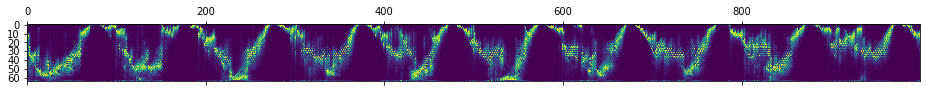

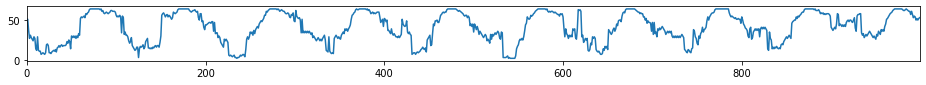

In [ ]:
px = np.ones(n_states)/n_states  #initial state is uniform (unknown values of x)
px_all = np.zeros((n_states,time_points))  #will save the state probability sequence here
for t in range(0,time_points):
  px = pxx_approx.dot(px)          #time update p(x,t) = Mp(x,t-1)
  likelihood = pzx.dot(vModulated[t,:].transpose())  #z'th column of pzx is the likelihood p(z(t)|x)
  px = np.multiply(px, likelihood)  #Bayes rule
  px = px / px.sum()                #normalize so it's a probability
  px_all[:,t]=px / px.max()  #save for display purposes
plt.figure(figsize=(12,2))
plt.matshow(px_all[:,0:1000])  #same as imshow()
dfPxAll = pd.DataFrame(px_all.transpose())
predicted_x = dfPxAll.idxmax(axis=1)  #Maximum Likelihood estimate
plt.figure(figsize=(16,1))
plt.plot(n_states - predicted_x[0:1000]);
ax = plt.gca()  # only to illustrate what `ax` is
ax.autoscale(enable=True, axis='x', tight=True)

,Torque,Biceps,Triceps,Envelope
0,-1.92092,0.000037,0.000061,-3.36693
1,-1.95486,0.000030,0.000058,-3.36415
2,-1.99559,0.000038,0.000066,-3.36139
3,-2.02953,0.000033,0.000069,-3.35864
4,-2.17207,0.000026,0.000062,-3.35591
...,...,...,...,...
15111,-2.31461,0.000040,0.000065,-2.21345
15112,-2.38249,0.000033,0.000070,-2.21296
15113,-2.28746,0.000031,0.000077,-2.21247
15114,-2.32140,0.000028,0.000066,-2.21198


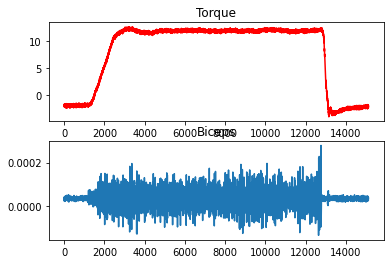

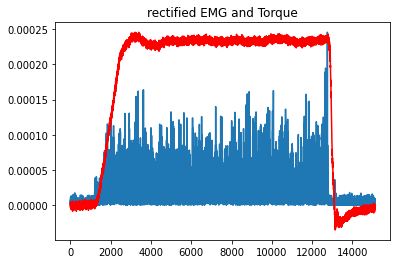

In [ ]:
#load the sample EMG data
arEMG = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/EMGdata.csv')
dfEMG = pd.DataFrame(arEMG)
plt.figure()
plt.subplot(211)
plt.plot(dfEMG['Torque'],'r')
plt.title('Torque')
plt.subplot(212)
plt.plot(dfEMG['Biceps'])
plt.title('Biceps')
wave_signal = dfEMG['Torque'].to_numpy()
wave_signal = wave_signal - wave_signal[0:200].mean()  #make start at zero
modulated_signal = dfEMG['Biceps'].to_numpy()
modulated_signal = modulated_signal - modulated_signal[0:200].mean()  #use the first few points to find the zero
modulated_signal = np.absolute(modulated_signal)  #rectify the EMG
time_points = len(wave_signal)
plt.figure()
plt.plot(modulated_signal)
plt.plot(wave_signal * modulated_signal.max()/wave_signal.max(),'r')
plt.title('rectified EMG and Torque')

dfEMG

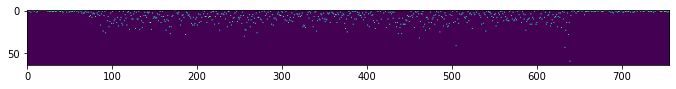

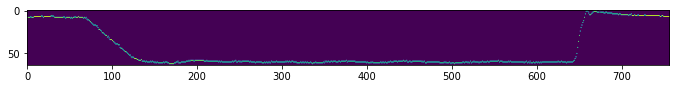

In [ ]:
#turn into probability vectors
n_states = 64   #this is arbitrary. sets the precision
vModulated = to_distributed(modulated_signal, n_states, time_points)
dfModulated = pd.DataFrame(data=vModulated, index=np.arange(time_points))
plt.figure(figsize=(14,1))
plt.imshow(vModulated[np.arange(0,time_points,20)].transpose())
vWave = to_distributed(wave_signal, n_states, time_points)
dfWave = pd.DataFrame(data=vWave, index=np.arange(time_points))
plt.figure(figsize=(14,1))
plt.imshow(vWave[np.arange(0,time_points,20)].transpose());

In [ ]:
n_features = n_states
n_hidden = n_states
predict_length = 1
model = Sequential()
model.add(Flatten(input_shape = (1,n_features)))
model.add(Dense(n_features, activation='softmax'))
model.compile(optimizer='adam', loss='categorical_crossentropy')
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_2 (Flatten)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 64)                4160      
                                                                 
Total params: 4,160
Trainable params: 4,160
Non-trainable params: 0
_________________________________________________________________


Epoch 1/10
851/851 [==============================] - 2s 2ms/step - loss: 3.7008 - val_loss: 2.9439
Epoch 2/10
851/851 [==============================] - 2s 2ms/step - loss: 3.1988 - val_loss: 2.2319
Epoch 3/10
851/851 [==============================] - 2s 2ms/step - loss: 3.0258 - val_loss: 1.8496
Epoch 4/10
851/851 [==============================] - 2s 2ms/step - loss: 2.9519 - val_loss: 1.6354
Epoch 5/10
851/851 [==============================] - 2s 2ms/step - loss: 2.9130 - val_loss: 1.4994
Epoch 6/10
851/851 [==============================] - 2s 2ms/step - loss: 2.8896 - val_loss: 1.4070
Epoch 7/10
851/851 [==============================] - 2s 2ms/step - loss: 2.8739 - val_loss: 1.3404
Epoch 8/10
851/851 [==============================] - 2s 2ms/step - loss: 2.8629 - val_loss: 1.2937
Epoch 9/10
851/851 [==============================] - 2s 2ms/step - loss: 2.8544 - val_loss: 1.2559
Epoch 10/10
851/851 [==============================] - 2s 2ms/step - loss: 2.8479 - val_loss: 1.2258

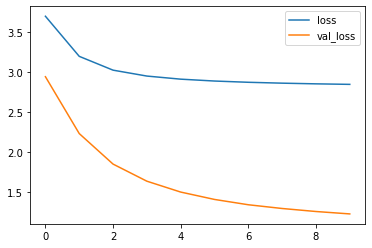

In [ ]:
#need to reshape the input data because numpy expects a 1xn_states array, rather than a vector of n_states.  this is why I use matlab.
model.fit(vWave.reshape(time_points,1,n_states),vModulated, validation_split=0.1, batch_size=16, epochs=10, verbose=1)
#model.fit(generator, epochs=5)  #if you want to do these in time sequence, which does not matter here
losses = pd.DataFrame(model.history.history)
losses.plot()

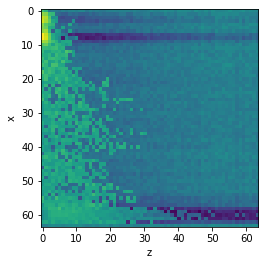

In [ ]:
pzx = np.exp(model.weights[0])
row_sums = pzx.sum(axis=1)
pzx = pzx / row_sums.reshape(n_states,1);
#pzx = pzx + 0.01  #make sure that it does not have any zeros
#pzx = pzx / row_sums.reshape(n_states,1);  #renormalize
plt.imshow(np.log(pzx))
plt.xlabel('z')
plt.ylabel('x');

In [ ]:
generator = TimeseriesGenerator(dfWave.values, dfWave.values, length =predict_length , batch_size=16)

n_features = n_states
n_hidden = n_states
predict_length = 1
model = Sequential()
model.add(Flatten(input_shape = (1,n_features)))
model.add(Dense(n_features, activation='softmax'))
model.compile(optimizer='adam', loss='categorical_crossentropy')
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_3 (Flatten)         (None, 64)                0         
                                                                 
 dense_3 (Dense)             (None, 64)                4160      
                                                                 
Total params: 4,160
Trainable params: 4,160
Non-trainable params: 0
_________________________________________________________________


In [ ]:
model.fit(generator, epochs=5)

Epoch 1/5
945/945 [==============================] - 3s 2ms/step - loss: 3.4253
Epoch 2/5
945/945 [==============================] - 2s 2ms/step - loss: 2.4343
Epoch 3/5
945/945 [==============================] - 2s 2ms/step - loss: 1.9972
Epoch 4/5
945/945 [==============================] - 2s 2ms/step - loss: 1.7955
Epoch 5/5
945/945 [==============================] - 2s 2ms/step - loss: 1.6768


/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:2: RuntimeWarning: overflow encountered in exp
  
/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:7: RuntimeWarning: divide by zero encountered in log
  import sys


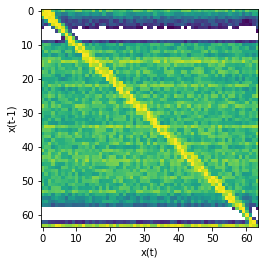

In [ ]:
prior_weight = 50   #how much to believe the prior relative to the measurement
pxx = np.exp(prior_weight*model.weights[0])
pxx = np.nan_to_num(pxx)
row_sums = pxx.sum(axis=1)
row_sums[row_sums==0]=1   #just in case there was no data
pxx = pxx / row_sums.reshape(n_states,1);
plt.imshow(np.log(pxx))
plt.xlabel('x(t)')
plt.ylabel('x(t-1)');

<Figure size 864x144 with 0 Axes>

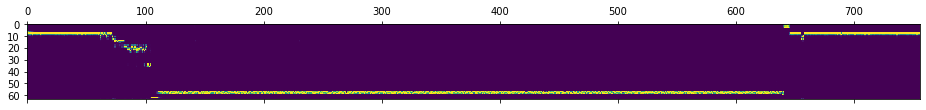

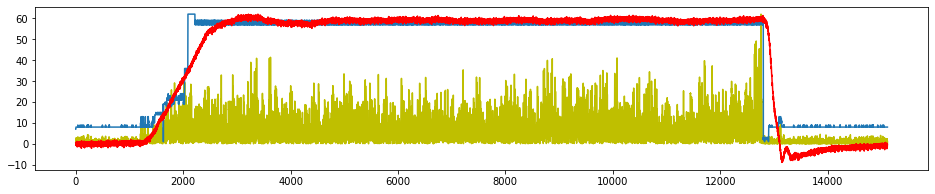

In [ ]:
px = np.ones(n_states)/n_states  #initial state is uniform (unknown values of x)
px_all = np.zeros((n_states,time_points))
for t in range(0,time_points):
  px = pxx.dot(px)          #time update p(x,t) = Mp(x,t-1)
  likelihood = pzx.dot(vModulated[t,:].transpose())  #z'th column of pzx is the likelihood p(z(t)|x)
  px = np.multiply(px, likelihood)  #Bayes rule
  px = px / px.sum()                #normalize so it's a probability
  px_all[:,t]=px / px.max()  #for display purposes
plt.figure(figsize=(12,2))
plt.matshow(px_all[:,np.arange(0,time_points,20)])
dfPxAll = pd.DataFrame(px_all.transpose())
predicted_x = dfPxAll.idxmax(axis=1)
plt.figure(figsize=(16,3))
plt.plot(modulated_signal*predicted_x.max()/modulated_signal.max(),'y');
plt.plot(predicted_x);
plt.plot(wave_signal*predicted_x.max()/wave_signal.max(),'r');